# Introduction

In this project, we evaulate the asymptotic distribution of the correlation coefficient between two random fields. 

In [1]:
import numpy as np 
import gstools as gs
import pandas as pd
import matplotlib.pyplot as plt
import time

# Simulations

First we simulate two isotropic Gaussian random fields and look at their semi-variograms. Note the semi-variogram is defined as $\gamma(s_1, s_2)  = 1/2\text{Var}(Z(s_1)-Z(s_2))$. 

shape of the random field: (100, 100)


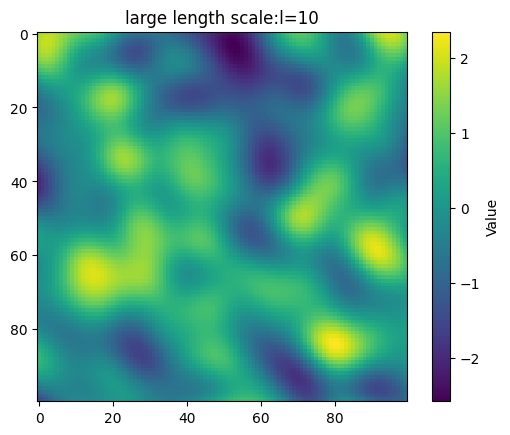

bin_center: [ 1.55563492  4.66690476  7.77817459 10.88944443 14.00071427 17.1119841
 20.22325394 23.33452378 26.44579362 29.55706345 32.66833329 35.77960313
 38.89087297 42.0021428  45.11341264]
gamma: [0.03974397 0.18508407 0.39899927 0.61912603 0.81289291 0.88963801
 0.87873231 0.84613826 0.82410687 0.84171528 0.89339971 0.9253158
 0.92354008 0.88232753 0.80663808]
The number of point pairs found for each bin: [197 193 189 185 270 175 171 167 163 237 153 149 145 141 137]
gamma_truth: [0.01882363 0.15720156 0.37816236 0.60589955 0.78545742 0.89967788
 0.9597045  0.9860975  0.99587991 0.99895119 0.99977067 0.99995693
 0.99999305 0.99999904 0.99999989]


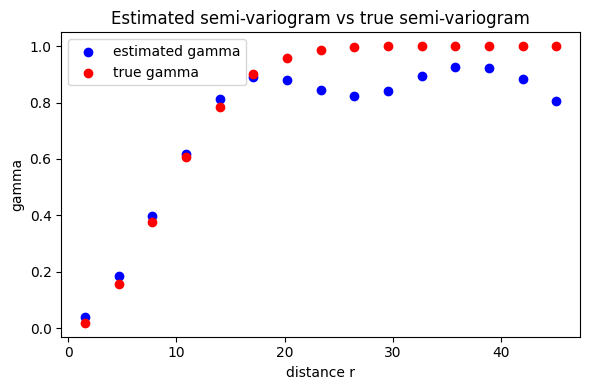

In [2]:
# explore gstools
# structured grid
nx = ny = 100
# old: origin at the left bottom cornoer
#x = y = range(nx)
# origin at the center
x = np.arange(nx) -nx//2
y = np.arange(ny) -ny//2

#print('X coordinates:', x, '\nY coordinates:', y)

# a larger length scale gives a smoother field
scale = 10
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)
U = srf.structured([x, y], seed = 1)
print('shape of the random field:', U.shape)
plt.imshow(U)
plt.colorbar(label="Value")
plt.title(f"large length scale:l={scale}")
plt.show()



# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)
print('gamma_truth:', gamma_truth)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()

# note under an isotropic field with variance 1, when the distance increases, covariance decreaes and  gamma increases and is close to 1. 

In [ ]:
# a smaller length scale gives a rougher field
scale = 5
model = gs.Gaussian(dim=2, var=1, len_scale=scale)
# of class gstools.filed.srf.SRF
srf = gs.SRF(model)
U = srf.structured([x, y],seed = 1)
plt.imshow(U)
plt.colorbar(label="Value")
plt.title(f"small length scale:l={scale}")
plt.show()

# estimate the empirical semivariogram gamma of the field
# for large input data, this method can take a long time to compute the variogram, therefore sampling_size specifies the number of data points to sample randomly
bin_center, gamma, counts = gs.vario_estimate(pos = (x, y), field = srf((x,y)), return_counts = True)
print('bin_center:', bin_center)
print('gamma:', gamma)
print('The number of point pairs found for each bin:', counts)
# the true value of the variogram corresponding to the squared exponential covariance function
gamma_truth = 1-np.exp(-(np.sqrt(3.141)/2*bin_center/scale)**2)

plt.figure(figsize=(6,4))
plt.scatter(bin_center, gamma, color='blue', label='estimated gamma')
plt.scatter(bin_center, gamma_truth, color='red',  label='true gamma')

plt.xlabel("distance r")
plt.ylabel("gamma")
plt.title("Estimated semi-variogram vs true semi-variogram")
plt.legend()
plt.tight_layout()
plt.show()


In [17]:
def gen_field(rho, nx=64, ny=None, var=1.0, len_scale=10.0, seed=None, M_trunc = None, return_corrdinate = False):
    """
    Generate a pair of correlated 2D Gaussian random fields with optional truncation.

    Parameters
    ----------
    rho : float
        Desired pointwise correlation between the two fields (between -1 and 1).
    nx : int, optional (default=64)
        Number of grid points in the x-direction.
    ny : int or None, optional (default=None)
        Number of grid points in the y-direction. If None, uses the same as `nx`.
    var : float, optional (default=1.0)
        Variance parameter for the Gaussian covariance model.
    len_scale : float, optional (default=10.0)
        Length scale parameter of the Gaussian covariance (larger length scale is smoother).
    seed : int or None, optional (default=None)
        Random seed for reproducibility. If None, uses a random seed.
    M_trunc : float or None, optional (default=None)
        Truncation threshold. If provided, both fields are clipped to [-M_trunc, M_trunc].

    Returns
    -------
    X, Y : ndarray
        Two 2D NumPy arrays of shape (nx, ny), representing correlated Gaussian fields.
        If `M_trunc` is not None, the arrays are truncated at ±M_trunc.

    Examples
    --------
    >>> X, Y = gen_field(rho=0.7, nx=50, len_scale=5.0, seed=42, M_trunc=2.0)
    >>> X.shape, Y.shape
    ((50, 50), (50, 50))
    """
    # if seed = None, rng.integers will genereate a random number
    rng = np.random.default_rng(seed)
    # check whether var can be a free parameter?
    model = gs.Gaussian(dim=2, var=var, len_scale=len_scale)
    srf = gs.SRF(model, seed=rng.integers(0, 1e9))

    # structured grid with origin at the center
    if ny is None:
        ny = nx

    origin = (nx//2, ny//2)
    #x = range(nx)
    #y = range(ny)
    x = np.arange(nx) - origin[0]
    y = np.arange(nx) - origin[1]
    results = []
    beta = np.sqrt(max(0.0, 1.0 - rho**2))
    # two independent fields
    U = srf.structured([x, y], seed=rng.integers(0, 1e9))
    V = srf.structured([x, y], seed=rng.integers(0, 1e9))

    # correlated pair of fields
    X = U
    Y = rho * U + beta * V

    # optional: correlated pair of truncated fields
    if M_trunc is not None:
        X = np.clip(X, -M_trunc, M_trunc)
        Y = np.clip(Y, -M_trunc, M_trunc)
    if return_corrdinate: 
        return (X,Y, x, y)
    else:
        return (X,Y)


X, Y, x, y = gen_field(rho=0, nx = 5, seed = 1, len_scale = 1, return_corrdinate = True)
print(X.shape, Y.shape)
print(x,y)

(5, 5) (5, 5)
[-2 -1  0  1  2] [-2 -1  0  1  2]


In [163]:
print(X.ravel().shape)
np.corrcoef(X.ravel(), Y.ravel())
nx = 10
ny = 10
x = np.arange(nx) - nx//2
y = np.arange(ny) - ny//2
xx, yy = np.meshgrid(x, y, indexing="ij")
print(xx)
print(yy)

(4096,)
[[-5 -5 -5 -5 -5 -5 -5 -5 -5 -5]
 [-4 -4 -4 -4 -4 -4 -4 -4 -4 -4]
 [-3 -3 -3 -3 -3 -3 -3 -3 -3 -3]
 [-2 -2 -2 -2 -2 -2 -2 -2 -2 -2]
 [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 1  1  1  1  1  1  1  1  1  1]
 [ 2  2  2  2  2  2  2  2  2  2]
 [ 3  3  3  3  3  3  3  3  3  3]
 [ 4  4  4  4  4  4  4  4  4  4]]
[[-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]
 [-5 -4 -3 -2 -1  0  1  2  3  4]]


In [ ]:
# back up
nx, ny = X.shape
    x = np.arange(nx) - nx//2
    y = np.arange(ny) - ny//2
    xx, yy = np.meshgrid(x, y, indexing="ij")
    l2_square = xx**2 + yy**2   # L2 norm squared gird
    # Count how many cells fall in each unique radius 
    unique_l2_square, counts = np.unique(l2_square, return_counts=True)
    unique_l2 = np.sqrt(unique_l2_square)
    

In [222]:
# the two are different 
print('corr (X,Y):', correlate2d(X, Y))
print('corr (Y,X):', correlate2d(Y, X))

corr (X,Y): [[-6.95549878e-02 -1.85092823e-01 -3.33800460e-01 ...  2.04337321e+00
   1.30737997e+00  6.38033634e-01]
 [-7.14156353e-02 -2.22248049e-01 -4.35762585e-01 ...  3.92712703e+00
   2.59375942e+00  1.30858977e+00]
 [-1.55761076e-02 -1.30285875e-01 -3.32782087e-01 ...  5.61683281e+00
   3.84022991e+00  2.00355859e+00]
 ...
 [ 8.74349489e+00  1.80457833e+01  2.78121247e+01 ...  2.07797870e+00
   1.37835146e+00  6.90519281e-01]
 [ 5.35652178e+00  1.11307417e+01  1.72735430e+01 ...  1.04667726e+00
   6.81253384e-01  3.37018100e-01]
 [ 2.43062472e+00  5.08772814e+00  7.95321438e+00 ...  3.73048455e-01
   2.35453186e-01  1.13991941e-01]]
corr (Y,X): [[ 1.13991941e-01  2.35453186e-01  3.73048455e-01 ...  7.95321438e+00
   5.08772814e+00  2.43062472e+00]
 [ 3.37018100e-01  6.81253384e-01  1.04667726e+00 ...  1.72735430e+01
   1.11307417e+01  5.35652178e+00]
 [ 6.90519281e-01  1.37835146e+00  2.07797870e+00 ...  2.78121247e+01
   1.80457833e+01  8.74349489e+00]
 ...
 [ 2.00355859e+00  3

In [37]:
import numpy as np
from scipy.signal import correlate2d, correlate
import tracemalloc

def est_exp_X0Yh(X, Y, return_counts_lags = False):
    """
    Estimate E[X_0 * Y_h] for all 2-D integer lags h=(hx,hy) on a grid.

    Parameters
    ----------
    X, Y : (nx, ny) 2D arrays (same shape)
        Input fields. 
    Returns
    -------
    E : (2*nx-1, 2*ny-1) array
        Estimated E[X_0 Y_h] at each lag h.
    counts : (2*nx-1, 2*ny-1) array
        Number of valid pairs at each lag.
    lags_x, lags_y : 1D arrays
        x and y coordinate of the lag
    """
    if X.shape != Y.shape:
        raise ValueError("X and Y must have the same shape")
    nx, ny = X.shape
    
    mask =  np.ones((nx, ny))
    
    # Sum of products at each lag
    S = correlate(X, Y, mode='full')
    # number of valid pairs at each lag (also known as edge correction for unbiased estimate)
    C = correlate(mask, mask, mode='full')
    # max number of pairs 
    # C = nx*ny
    # estimate of the expectaion 
    E = S/C
    if not return_counts_lags: 
        return E
    else: 
        lags_x = np.arange(-(nx-1), nx)
        lags_y = np.arange(-(ny-1), ny)
        return S, C, E, lags_x, lags_y

#X = np.array([1,2,3,4]).reshape((2,2))
#Y = np.array([0,1,1,0]).reshape((2,2))
nx = 100
X = np.random.normal(size = (nx,nx))
Y = np.random.normal(size = (nx,nx))
start = time.time()
tracemalloc.start()
res = est_exp_X0Yh(X, Y, True)
# Get current and peak memory usage
current, peak = tracemalloc.get_traced_memory()
print(f"Peak memory usage: {peak / 10**6:.2f} MB")
tracemalloc.stop()
end = time.time()
print(f"Runtime: {end - start:.4f} seconds")
print(res)

Peak memory usage: 1.69 MB
Runtime: 0.0100 seconds
(array([[-0.43777545,  2.19630004, -2.90762063, ...,  0.20297348,
         1.53358557, -2.66767189],
       [ 0.89982174,  0.80860608, -4.30669839, ..., -0.34704069,
         0.91453078, -1.53487622],
       [ 0.67062096, -3.15248515, 14.48571701, ..., -3.08842796,
         1.40434004,  0.3139089 ],
       ...,
       [ 0.91096312, -2.14756443,  1.76711984, ..., -1.85445823,
         0.20453166, -0.57603397],
       [-1.06062229,  2.34461552, -0.48467301, ...,  0.94210934,
        -0.37054791,  0.51418433],
       [-0.70689008,  2.14822195, -0.86338007, ..., -0.56497947,
         0.58940457, -0.08457388]]), array([[1., 2., 3., ..., 3., 2., 1.],
       [2., 4., 6., ..., 6., 4., 2.],
       [3., 6., 9., ..., 9., 6., 3.],
       ...,
       [3., 6., 9., ..., 9., 6., 3.],
       [2., 4., 6., ..., 6., 4., 2.],
       [1., 2., 3., ..., 3., 2., 1.]]), array([[-0.43777545,  1.09815002, -0.96920688, ...,  0.06765783,
         0.76679279, -2.667

In [41]:
np.ones(X)

ValueError: maximum supported dimension for an ndarray is 32, found 100

In [13]:
x1,y1 = np.meshgrid((-1,0,1), (-2,-1,0,1,2))
print(x1)
print(y1)


[[-1  0  1]
 [-1  0  1]
 [-1  0  1]
 [-1  0  1]
 [-1  0  1]]
[[-2 -2 -2]
 [-1 -1 -1]
 [ 0  0  0]
 [ 1  1  1]
 [ 2  2  2]]


In [40]:
nx =3
ny =3
M = (2,2)
lags_x = np.arange(-(nx-1), nx)
lags_y = np.arange(-(ny-1), ny)
lags_x_all, lags_y_all = np.meshgrid(lags_x, lags_y)
(np.abs(lags_x_all)<M[0])*(np.abs(lags_y_all)<M[1])*(1-np.abs(lags_x_all)/M[0])*(1-np.abs(lags_y_all)/M[1])

array([[1., 1., 1.],
       [1., 1., 1.]])

In [58]:
import time
def corr(X, Y, M=None, true_rho = None, method = 'bartlett'):
    start_time = time.time()
    if X.shape != Y.shape:
        raise ValueError("X and Y must have the same shape")
    nx, ny = X.shape
    X_standard =  (X-X.mean())/X.std()
    Y_standard =  (Y-Y.mean())/Y.std()
    #--------weight function and truncation lag numbder -----------
    if M is None:
        M = np.floor((nx/5, ny/5))
    lags_x = np.arange(-(nx-1), nx)
    lags_y = np.arange(-(ny-1), ny)
    lags_x_all, lags_y_all = np.meshgrid(lags_x, lags_y)
    if method == 'bartlett':
        weights =(np.abs(lags_x_all)<M[0])*(np.abs(lags_y_all)<M[1])*(1-np.abs(lags_x_all)/M[0])*(1-np.abs(lags_y_all)/M[1])
    if method == 'constant':
        weights = (np.abs(lags_x_all)<M[0])*(np.abs(lags_y_all)<M[1])
    if method == 'naive':
        # known to perform poorly, testing only!!
        weights = np.ones((len(lags_x),len(lags_y)))
    #print(weights)
    #print(weights.shape)
    #print(X_standard.mean())
    #print(X_standard.std())
    rho_est = np.corrcoef(X.ravel(), Y.ravel())[0, 1]
    X_standard_square = X_standard **2
    Y_standard_square = Y_standard **2
    X_standard_Y_standard = X_standard * Y_standard
    #print(X_standard_Y_standard.shape)
    if true_rho == 0:
        T1= T2 = 0
    else:
        T1 = (est_exp_X0Yh(X_standard_square, X_standard_square) + est_exp_X0Yh(Y_standard_square, Y_standard_square) + 
              est_exp_X0Yh(X_standard_square, Y_standard_square) + est_exp_X0Yh(Y_standard_square, X_standard_square))
        T2 = (est_exp_X0Yh(X_standard_square, X_standard_Y_standard) + est_exp_X0Yh(X_standard_Y_standard, X_standard_square) +
              est_exp_X0Yh(X_standard_Y_standard, Y_standard_square) + est_exp_X0Yh(Y_standard_square, X_standard_Y_standard))
    T3 = est_exp_X0Yh(X_standard_Y_standard, X_standard_Y_standard)
    #print(np.sqrt(np.sum(T3)/(nx*ny)))
    if true_rho is None:
        h  = weights*(1/4*(rho_est**2)*T1 -1/2*rho_est*T2 +T3)
    else:
        h  = weights*(1/4*(true_rho**2)*T1 -1/2*true_rho*T2 +T3)
    #print(h)
    #print(h.shape)
    #print(np.max(h))
    var = np.sum(h)/(nx*ny)
    #print(var)
    if var<0:
        se = -1
    else:
        se = np.sqrt(var)
    runtime_secs = time.time() - start_time
    return rho_est, se, runtime_secs
corr(X,Y, M = (2,2), true_rho = 0, method = 'naive')
corr(X,Y, M = (2,2), true_rho = 0, method = 'bartlett')

(0.004515205483101076, 0.009890940051974065, 0.009521007537841797)

In [66]:
def sim_single(rho, m_sim=5, nx=64, ny=None, var=1.0, len_scale=10.0, seed=None, M_trunc =None,
               return_summary = True):
    """
    Returns
    -------
    pandas.DataFrame with columns ['sim_id', 'pearson_r'].
    """
    # if seed = None, rng.integers will genereate a random number
    rng = np.random.default_rng(seed)
    
    if ny is None:
        ny = nx
        
   # if M_trunc is None: 
   #     rho_final = rho
   # else:
   #     rho_final = get_rho_trunc(rho, nx, ny, var, len_scale, seed, M_trunc):    
    
    results = []

    for i in range(1, m_sim+1):
        #? look at len_scale, this may depend on field size
        X,Y = gen_field(rho, nx, ny, var, len_scale, seed=rng.integers(0, 1e9), M_trunc = M_trunc)

        #print('shape of X:', X.shape, 'shape of Y:', Y.shape)

        # Pearson correlation and se
        est, se, runtime_secs = corr(X,Y, true_rho = 0)
        # python list append is similar to preallocate and then fill, faster than concat a row to a pandas dataframe
        results.append({"sim_id": i, "est": est, "se": se, "runtime": runtime_secs})

    results = pd.DataFrame(results) 
    results = results.assign(lower = results["est"]-1.96*results["se"], 
                             upper = results["est"]+1.96*results["se"])
    results = results.assign(cover = 1*(rho<=results["upper"]) & (rho>= results["lower"]))
    if return_summary:
        results = pd.DataFrame({'cover_mean': results["cover"].mean(),
                                'est_mean': results['est'].mean(),
                                'est_sd': results['est'].std(),
                                'se_mean': results['se'].mean(),
                                'runtime_mean': results['runtime'].mean()},
                              index = [0])
    results = results.assign(rho = rho, nx=nx, ny=ny, len_scale=len_scale, M_trunc=M_trunc, m_sim = m_sim) 
    return results


df = sim_single(rho=0, m_sim=200, nx=100, len_scale=0.1, seed=1, return_summary = True)
print(df)

   cover_mean  est_mean    est_sd   se_mean  runtime_mean  rho   nx   ny  \
0       0.985 -0.000325  0.009761  0.009862      0.008411    0  100  100   

   len_scale M_trunc  m_sim  
0        0.1    None    200  


In [128]:
# create various simulation settings
from itertools import product

nx_ls = [100,200,500,1000]
rho_ls = [0]
len_scale_ls = [0.1]
setting_df = pd.DataFrame(product(nx_ls, rho_ls, len_scale_ls), columns=['nx', 'rho', 'len_scale'])
print(setting_df)

     nx  rho  len_scale
0   100    0        0.1
1   200    0        0.1
2   500    0        0.1
3  1000    0        0.1


In [136]:
def sim_multiple(setting_df, m_sim, return_summary = False):
    results = []
    for i in setting_df.index:
        print(
            f'----performing simulation, current setting number: {i + 1}, remaining settings: {setting_df.shape[0] - i - 1}----')
        results_single = sim_single(rho=setting_df['rho'][i], m_sim=m_sim, nx=setting_df['nx'][i], len_scale=setting_df['len_scale'][i], return_summary = return_summary)
        results_single = results_single.assign(setting_id = i+1)
        results.append(results_single)
    results = pd.concat(results, ignore_index=True)
    return results
    
sim_multiple(setting_df, m_sim=2, return_summary = False)


----performing simulation, current setting number: 1, remaining settings: 3----
----performing simulation, current setting number: 2, remaining settings: 2----
----performing simulation, current setting number: 3, remaining settings: 1----
----performing simulation, current setting number: 4, remaining settings: 0----


,sim_id,est,se,runtime,lower,upper,cover,rho,nx,ny,len_scale,M_trunc,m_sim,setting_id
0,1,0.008210,0.008210,0.005000,-0.007881,0.024301,True,0,100,100,0.1,None,2,1
1,2,-0.016391,0.016391,0.004000,-0.048518,0.015735,True,0,100,100,0.1,None,2,1
2,1,0.001765,0.001765,0.022862,-0.001695,0.005225,True,0,200,200,0.1,None,2,2
3,2,0.001060,0.001060,0.018999,-0.001018,0.003139,True,0,200,200,0.1,None,2,2
4,1,0.000043,0.000043,0.131644,-0.000041,0.000127,True,0,500,500,0.1,None,2,3
5,2,-0.000171,0.000171,0.133281,-0.000507,0.000165,True,0,500,500,0.1,None,2,3
6,1,0.000875,0.000875,0.499349,-0.000840,0.002589,True,0,1000,1000,0.1,None,2,4
7,2,-0.000387,0.000387,0.539523,-0.001147,0.000372,True,0,1000,1000,0.1,None,2,4


In [142]:
import joblib
#out1 = sim_multiple(setting_df, m_sim=100, return_summary = False)
joblib.dump(out1, 'results/out1')

['results/out1']

In [141]:
out1

,sim_id,est,se,runtime,lower,upper,cover,rho,nx,ny,len_scale,M_trunc,m_sim,setting_id
0,1,0.008510,0.008510,0.005000,-0.008169,0.025189,True,0,100,100,0.1,None,100,1
1,2,0.005012,0.005012,0.000000,-0.004811,0.014835,True,0,100,100,0.1,None,100,1
2,3,0.001420,0.001420,0.001804,-0.001363,0.004204,True,0,100,100,0.1,None,100,1
3,4,0.012900,0.012900,0.000000,-0.012384,0.038184,True,0,100,100,0.1,None,100,1
4,5,-0.000152,0.000152,0.000000,-0.000449,0.000146,True,0,100,100,0.1,None,100,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,96,-0.001145,0.001145,0.490240,-0.003388,0.001099,True,0,1000,1000,0.1,None,100,4
396,97,-0.000390,0.000390,0.505577,-0.001155,0.000374,True,0,1000,1000,0.1,None,100,4
397,98,-0.000315,0.000315,0.521069,-0.000933,0.000302,True,0,1000,1000,0.1,None,100,4
398,99,-0.000720,0.000720,0.599581,-0.002130,0.000691,True,0,1000,1000,0.1,None,100,4


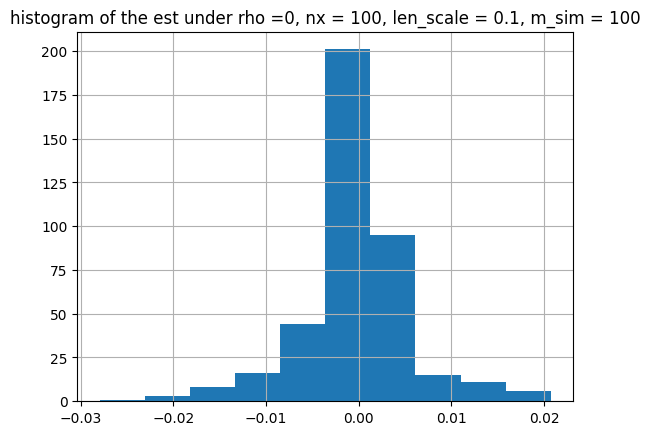

In [143]:
df = joblib.load('results/out1')

In [151]:
df['setting_id'].unique()

array([1, 2, 3, 4], dtype=int64)

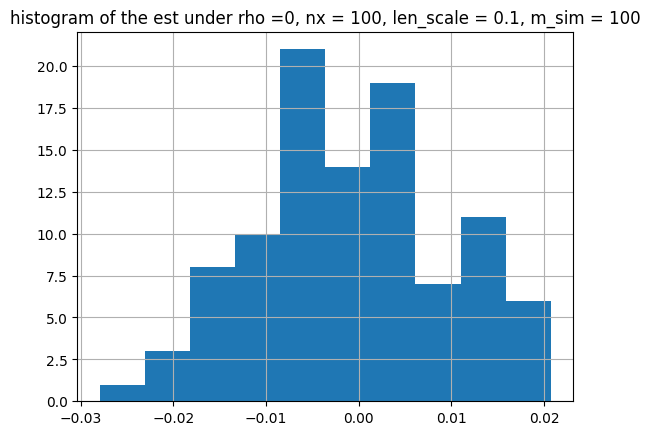

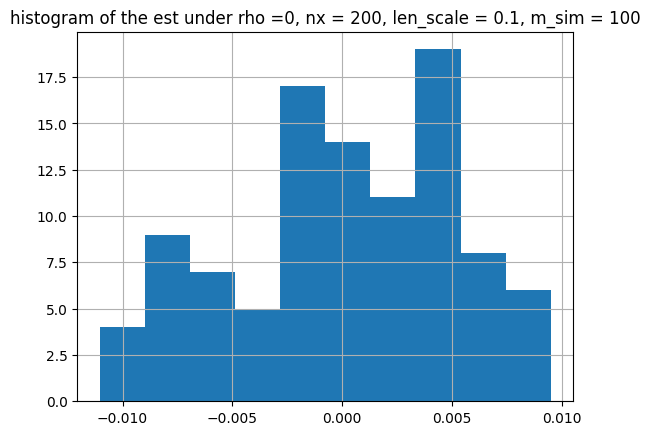

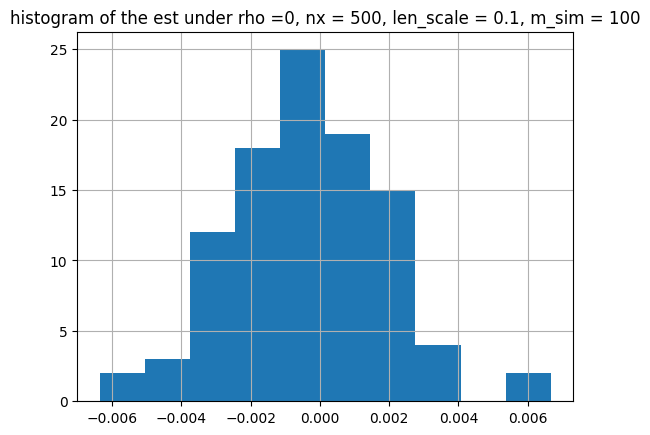

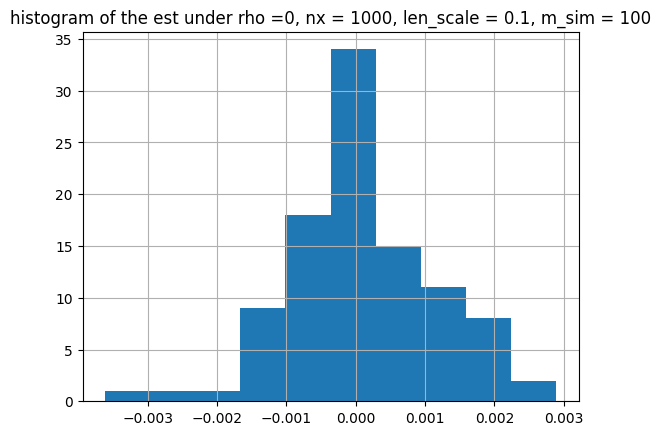

In [163]:
def plot_est(df):
    for i in df['setting_id'].unique():
        df_single = df[df["setting_id"] ==i].reset_index(drop=True)
        df_single['est'].hist()
        plt.title(f"histogram of the est under rho ={df_single['rho'][1]}, nx = {df_single['nx'][1]}, len_scale = {df_single['len_scale'][1]}, m_sim = {df_single['m_sim'][1]}")
        plt.show()
plot_est(df)

In [ ]:
# backup codes
def get_rho_trunc(rho, nx=64, ny=None, var=1.0, len_scale=10.0, seed=None, M_trunc = 10000):    
    # if seed = None, rng.integers will genereate a random number
    rng = np.random.default_rng(seed)
    X_point_ls = []
    Y_point_ls = []
    if ny is None:
        ny = nx
    # the location of the point does not matter due to stationarity, here i use center of the field just for convenience 
    X_center = int(np.ceil(nx/2))
    Y_center = int(np.ceil(ny/2))
    # this step may take a long time with a large loop
    # ?but maybe we do not need to do this because when M_trunc is very large, the rho after truncation should be very similar to the rho before truncation
    # also in reality, the gaussian field generated is already bounded due to computer storage 
    for i in range(50):
        X,Y = gen_field(rho, nx, ny, var, len_scale, seed=rng.integers(0, 1e9), M_trunc = M_trunc)
        X_point_ls.append(X[X_center,Y_center])
        Y_point_ls.append(Y[X_center,Y_center])
    return np.corrcoef(X_point_ls, Y_point_ls)[0, 1]
get_rho_trunc(0.5, nx=64, ny=None, var=1.0, len_scale=10.0, seed=1, M_trunc = 10000)